# Digit + angle → image

On donne au global workspace un chiffre et un angle (domaine digit), et on regarde l'image produite :
digit → GW → latent VAE → décodeur du VAE → image.

In [19]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from cfg_tools import load_config_files

from numb_project.constants import BASE, CONFIG_FILE, CONFIG_FOLDER, DEVICE, GW_CHECKPOINT_FOLDER
from numb_project.utils import angle_to_cos_sin
from numb_project.domain_module import get_domains_config
from numb_project.gw_model import MyGlobalWorkspace, get_global_workspace_mods

CKPT = f"{GW_CHECKPOINT_FOLDER}/rotation_test.ckpt"

torch.set_grad_enabled(False)  # notebook d'évaluation uniquement

config = load_config_files(CONFIG_FOLDER, use_cli=False, load_files=[CONFIG_FILE])[0]
domain_configs = get_domains_config(['image', 'digit'], config['domains']['digit'])
gw_mod, selection_mod, loss_mod, operation_rotate_pixel_mod, operation_rotate_gw_mod = get_global_workspace_mods(config, domain_configs)

gw = MyGlobalWorkspace.load_from_checkpoint(
    CKPT,
    gw_mod=gw_mod,
    selection_mod=selection_mod,
    loss_mod=loss_mod,
    operation_rotate_pixel_mod=operation_rotate_pixel_mod,
    operation_rotate_gw_mod=operation_rotate_gw_mod,
    map_location=DEVICE,
    weights_only=False,
)
gw.eval()
device = gw.device
mnist_vae = gw.gw_mod.domain_mods["image"].vae

In [20]:
def digit_and_angle_to_image(digits: list[int], angles_deg: list[float]) -> torch.Tensor:
    """digit + angle -> vecteur digit (one-hot + cos/sin) -> état GW (tanh de
    l'encodage, cf GWModule.fuse) -> latent VAE -> image."""
    labels = torch.tensor(digits, device=device)
    angles = torch.tensor(angles_deg, device=device, dtype=torch.float)
    digit_vector = torch.cat([F.one_hot(labels, BASE).float(), angle_to_cos_sin(angles)], dim=-1)
    gw_state = gw.gw_mod.fusion_activation_fn(gw.gw_mod.gw_encoders["digit"](digit_vector))
    return mnist_vae.decoder(gw.gw_mod.gw_decoders["image"](gw_state))


def show(images: torch.Tensor, titles: list[str], n_cols: int = 8) -> None:
    n_rows = (len(images) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.3, n_rows * 1.8), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image[0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.show()

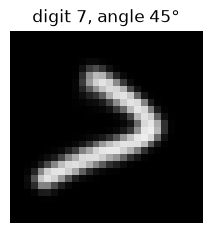

In [21]:
# --- Un chiffre, un angle : modifier ces deux valeurs ---
digit = 7
angle = 45.0

image = digit_and_angle_to_image([digit], [angle])
plt.figure(figsize=(2.5, 2.5))
plt.imshow(image[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
plt.title(f"digit {digit}, angle {angle:.0f}°")
plt.axis("off")
plt.show()

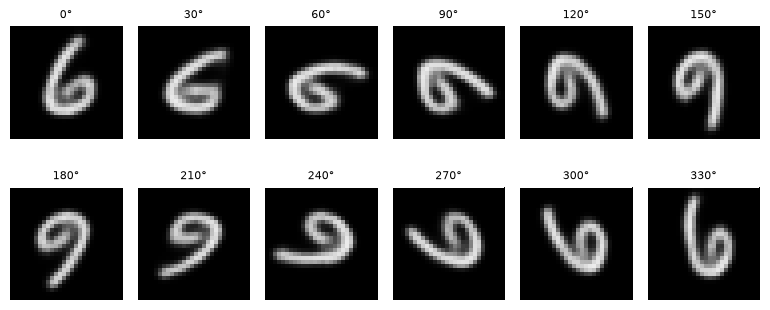

In [22]:
# --- Un chiffre à tous les angles (pas de 30°) ---
digit = 6
angles = [float(a) for a in range(0, 360, 30)]

show(digit_and_angle_to_image([digit] * len(angles), angles), [f"{a:.0f}°" for a in angles], n_cols=6)

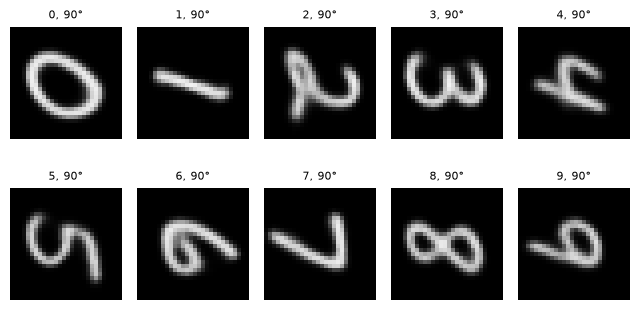

In [23]:
# --- Tous les chiffres au même angle ---
angle = 90.0
digits = list(range(BASE))

show(digit_and_angle_to_image(digits, [angle] * BASE), [f"{d}, {angle:.0f}°" for d in digits], n_cols=5)

In [24]:
# --- Exploration interactive : curseurs pour le chiffre et l'angle ---
from ipywidgets import FloatSlider, IntSlider, interact


@interact(digit=IntSlider(min=0, max=BASE - 1, value=7), angle=FloatSlider(min=0, max=359, step=1, value=0))
def explore(digit: int, angle: float) -> None:
    image = digit_and_angle_to_image([digit], [angle])
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(image[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    plt.title(f"digit {digit}, angle {angle:.0f}°")
    plt.axis("off")
    plt.show()

interactive(children=(IntSlider(value=7, description='digit', max=9), FloatSlider(value=0.0, description='angl…

## Image → digit

On donne une image du test set de MNIST, tournée d'un angle choisi, et on lit le digit produit par le GW :
image → latent VAE → GW → digit, dont on lit le chiffre (argmax du one-hot) et l'angle (à partir de cos, sin).

In [25]:
from torchvision import datasets, transforms

from numb_project.utils import rotate_images

test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())


def image_to_digit_and_angle(images: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """image -> latent VAE (mu) -> état GW (tanh de l'encodage) -> digit.
    Renvoie le chiffre prédit et l'angle prédit (en degrés, dans [0, 360[)."""
    mu, _ = mnist_vae.encoder(images)
    gw_state = gw.gw_mod.fusion_activation_fn(gw.gw_mod.gw_encoders["image"](mu))
    digits = gw.gw_mod.gw_decoders["digit"](gw_state)
    angles = torch.rad2deg(torch.atan2(digits[:, BASE + 1], digits[:, BASE])).round() % 360
    return digits[:, :BASE].argmax(dim=-1), angles


def rotated_test_images(indices: list[int], angles_deg: list[float]) -> tuple[torch.Tensor, list[int]]:
    images = torch.stack([test_dataset[i][0] for i in indices]).to(device)
    angles = torch.tensor(angles_deg, device=device, dtype=torch.float)
    return rotate_images(images, angles), [test_dataset[i][1] for i in indices]

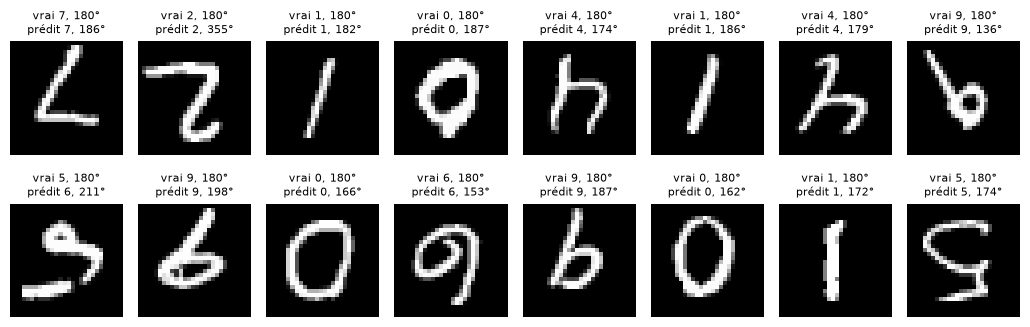

In [31]:
# --- Quelques images du test set, toutes tournées du même angle : modifier ces valeurs ---
indices = list(range(16))
angle = 180.0

images, true_digits = rotated_test_images(indices, [angle] * len(indices))
pred_digits, pred_angles = image_to_digit_and_angle(images)
show(images, [f"vrai {d}, {angle:.0f}°\nprédit {p}, {a:.0f}°" for d, p, a in zip(true_digits, pred_digits.tolist(), pred_angles.tolist())])

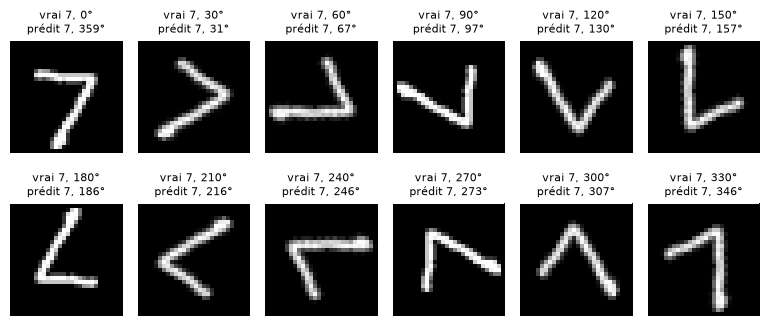

In [27]:
# --- Une image à tous les angles (pas de 30°) ---
index = 0
angles = [float(a) for a in range(0, 360, 30)]

images, true_digits = rotated_test_images([index] * len(angles), angles)
pred_digits, pred_angles = image_to_digit_and_angle(images)
show(images, [f"vrai {d}, {a:.0f}°\nprédit {p}, {pa:.0f}°" for d, a, p, pa in zip(true_digits, angles, pred_digits.tolist(), pred_angles.tolist())], n_cols=6)

In [ ]:
# --- Exploration interactive : curseurs pour l'image et l'angle ---
@interact(index=IntSlider(min=0, max=len(test_dataset) - 1, value=0), angle=FloatSlider(min=0, max=359, step=5, value=0))
def explore_image(index: int, angle: float) -> None:
    images, true_digits = rotated_test_images([index], [angle])
    pred_digit, pred_angle = image_to_digit_and_angle(images)
    plt.figure(figsize=(2.5, 2.5))
    plt.imshow(images[0, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)
    plt.title(f"vrai {true_digits[0]}, {angle:.0f}°\nprédit {pred_digit.item()}, {pred_angle.item():.0f}°")
    plt.axis("off")
    plt.show()

interactive(children=(IntSlider(value=0, description='index', max=9999), FloatSlider(value=0.0, description='a…